In [1]:
!pip install -q transformers datasets accelerate scikit-learn

In [2]:
import numpy as np
import pandas as pd
import torch
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)
from sklearn.pipeline import make_pipeline, make_union
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

GPU: Tesla T4


In [3]:
base = "https://raw.githubusercontent.com/Husnainhassan11/roman-urdu-sentiment-analysis/main/Data/"

train_df = pd.read_csv(base + "train.csv")
val_df = pd.read_csv(base + "val.csv")
print(len(train_df), len(val_df))      # should print 15596 1949

labels = ["Negative", "Neutral", "Positive"]
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}
for d in (train_df, val_df):
    d["labels"] = d["label"].map(label2id)

15596 1949


In [4]:
checkpoint = "xlm-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

def tokenize(batch):
    return tokenizer(batch["sentence"], truncation=True, max_length=128)

def to_dataset(d):
    ds = Dataset.from_pandas(d[["sentence", "labels"]].reset_index(drop=True))
    return ds.map(tokenize, batched=True)

train_ds, val_ds = to_dataset(train_df), to_dataset(val_df)
print(checkpoint, id2label, len(train_ds), len(val_ds))

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/15596 [00:00<?, ? examples/s]

Map:   0%|          | 0/1949 [00:00<?, ? examples/s]

xlm-roberta-base {0: 'Negative', 1: 'Neutral', 2: 'Positive'} 15596 1949


In [5]:
def compute_metrics(eval_pred):
    logits, y_true = eval_pred
    y_pred = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro")}

# A fresh model, so training starts from the pretrained weights
model = AutoModelForSequenceClassification.from_pretrained(
    checkpoint, num_labels=3, id2label=id2label, label2id=label2id)

args = TrainingArguments(
    output_dir="xlmr-roman-urdu-v2",
    learning_rate=3e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=6,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=True,
    seed=42,
    report_to="none",
)

trainer = Trainer(
    model=model, args=args,
    train_dataset=train_ds, eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,0.898389,0.614161,0.602680
2,0.984403,0.841900,0.633145,0.607235
3,0.832506,0.795307,0.667522,0.659053
4,0.724102,0.828241,0.674192,0.670184


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,0.898389,0.614161,0.602680
2,0.984403,0.841900,0.633145,0.607235
3,0.832506,0.795307,0.667522,0.659053
4,0.724102,0.828241,0.674192,0.670184
5,0.617974,0.891885,0.661365,0.656734
6,0.533750,0.924530,0.663417,0.658100


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2928, training_loss=0.699302438829766, metrics={'train_runtime': 844.6178, 'train_samples_per_second': 110.791, 'train_steps_per_second': 3.467, 'total_flos': 4033518415902360.0, 'train_loss': 0.699302438829766, 'epoch': 6.0})

In [6]:
history = pd.DataFrame([x for x in trainer.state.log_history if "eval_macro_f1" in x])
history[["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]].round(3)

,epoch,eval_loss,eval_accuracy,eval_macro_f1
0,1.0,0.898,0.614,0.603
1,2.0,0.842,0.633,0.607
2,3.0,0.795,0.668,0.659
3,4.0,0.828,0.674,0.670
4,5.0,0.892,0.661,0.657
5,6.0,0.925,0.663,0.658


              precision    recall  f1-score   support

    Negative      0.617     0.683     0.648       523
     Neutral      0.743     0.667     0.703       845
    Positive      0.643     0.676     0.659       581

    accuracy                          0.674      1949
   macro avg      0.668     0.675     0.670      1949
weighted avg      0.679     0.674     0.675      1949



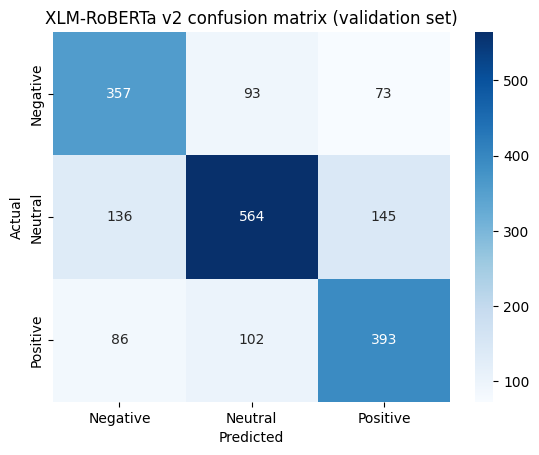

In [7]:
out = trainer.predict(val_ds)
y_true = out.label_ids
y_pred = out.predictions.argmax(-1)

print(classification_report(y_true, y_pred, target_names=labels, digits=3))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("XLM-RoBERTa v2 confusion matrix (validation set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [8]:
features = make_union(
    TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True),
)
lr = make_pipeline(features, LogisticRegression(max_iter=1000, C=3))
lr.fit(train_df["sentence"].str.lower(), train_df["label"])

print("Class order:", lr.classes_)     # must be ['Negative' 'Neutral' 'Positive']

p_lr = lr.predict_proba(val_df["sentence"].str.lower())
p_x = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()

for w in [0.0, 0.3, 0.5, 0.7, 1.0]:
    p = w * p_x + (1 - w) * p_lr
    print(f"weight on XLM-R = {w}: macro-F1 = {f1_score(y_true, p.argmax(1), average='macro'):.3f}")

Class order: ['Negative' 'Neutral' 'Positive']
weight on XLM-R = 0.0: macro-F1 = 0.671
weight on XLM-R = 0.3: macro-F1 = 0.683
weight on XLM-R = 0.5: macro-F1 = 0.687
weight on XLM-R = 0.7: macro-F1 = 0.681
weight on XLM-R = 1.0: macro-F1 = 0.670


In [9]:
sample = val_df.sample(100, random_state=7).reset_index(drop=True)
mine = []
for i, s in enumerate(sample["sentence"]):
    print(f"\n{i+1}/100: {s}")
    a = input("n = Negative, u = Neutral, p = Positive: ").strip().lower()
    mine.append({"n": "Negative", "u": "Neutral", "p": "Positive"}.get(a, "Neutral"))

sample["mine"] = mine
print("My agreement with the dataset labels:", round((sample["mine"] == sample["label"]).mean() * 100, 1), "%")


1/100: Dekh bc ye Meri story bss isi lye iss Eid Socha rehn dy
n = Negative, u = Neutral, p = Positive: n

2/100: hehe apko pta yeh kis ne edit ki? :P
n = Negative, u = Neutral, p = Positive: n

3/100: Is ijlaas mein Quaid e Azam Mohammed Ali Jinnah ne Allama Raghib Ahsan ko khiraj e tehseen pesh karte hue kaha tha
n = Negative, u = Neutral, p = Positive: p

4/100: Is kheel ke sare geet super hit howae aur is ke sath hi kamyabi ne un ke qadam chomme
n = Negative, u = Neutral, p = Positive: p

5/100: Ve nakhra gori da shawa !!! The ending thou soo funny n cute  hai na?
n = Negative, u = Neutral, p = Positive: p

6/100: Hm sa to parhya hua paper bi pora attempt nahi hota
n = Negative, u = Neutral, p = Positive: u

7/100: AMANTECH ne wada nibhaya
n = Negative, u = Neutral, p = Positive: p

8/100: Aj to beech raastay mein Nabia ne kohni maar k b ek dikhaayi thi phase 2 ki sarak per 😂😂
n = Negative, u = Neutral, p = Positive: n

9/100: Bachon ki nigehdasht ke hawale se Reham Khan ka kehna 

In [10]:
from huggingface_hub import notebook_login
notebook_login()

In [11]:
trainer.model.push_to_hub("roman-urdu-sentiment-xlmr")
tokenizer.push_to_hub("roman-urdu-sentiment-xlmr")

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...pcl3iyt/model.safetensors:   0%|          | 13.5kB / 1.11GB            

Validating                    :           |   0%            

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mp3dm0jb5n/tokenizer.json: 100%|##########| 17.1MB / 17.1MB            

Validating                    :           |   0%            

CommitInfo(commit_url='https://huggingface.co/husnainhassan/roman-urdu-sentiment-xlmr/commit/30eb72e14a6fb9d7aa2eb6c8248386e3515f5233', commit_message='Upload tokenizer', commit_description='', oid='30eb72e14a6fb9d7aa2eb6c8248386e3515f5233', pr_url=None, repo_url=RepoUrl('https://huggingface.co/husnainhassan/roman-urdu-sentiment-xlmr', endpoint='https://huggingface.co', repo_type='model', repo_id='husnainhassan/roman-urdu-sentiment-xlmr'), pr_revision=None, pr_num=None)

In [12]:
test_df = pd.read_csv(base + "test.csv")
test_df["labels"] = test_df["label"].map(label2id)
test_ds = to_dataset(test_df)

out_t = trainer.predict(test_ds)
y_t = out_t.label_ids
p_x_t = torch.softmax(torch.tensor(out_t.predictions), dim=-1).numpy()
p_lr_t = lr.predict_proba(test_df["sentence"].str.lower())

preds = {
    "TF-IDF + LR": p_lr_t.argmax(1),
    "XLM-R (epoch 4)": p_x_t.argmax(1),
    "Ensemble 50/50": (0.5 * p_x_t + 0.5 * p_lr_t).argmax(1),
}

rows = []
for name, pr in preds.items():
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_t, pr),
                 "Macro-F1": f1_score(y_t, pr, average="macro")})
print(pd.DataFrame(rows).set_index("Model").round(3))

# Is the ensemble really better, or is it luck? Re-sample the test set 1000 times.
rng = np.random.default_rng(42)
idx = rng.integers(0, len(y_t), (1000, len(y_t)))
def boot(pr):
    return np.array([f1_score(y_t[i], pr[i], average="macro") for i in idx])

diff = boot(preds["Ensemble 50/50"]) - boot(preds["TF-IDF + LR"])
print("Ensemble minus TF-IDF, macro-F1: average", diff.mean().round(3),
      "| 95% range", np.percentile(diff, [2.5, 97.5]).round(3))

Map:   0%|          | 0/1950 [00:00<?, ? examples/s]

                 Accuracy  Macro-F1
Model                              
TF-IDF + LR         0.680     0.672
XLM-R (epoch 4)     0.667     0.663
Ensemble 50/50      0.688     0.683
Ensemble minus TF-IDF, macro-F1: average 0.011 | 95% range [-0.005  0.03 ]
